## EDA 

1. We first have to load our dataset.


In [13]:
from pathlib import Path

import pandas as pd


def find_project_root() -> Path:
    path = Path.cwd().resolve()
    for candidate in [path, *path.parents]:
        data_file = candidate / "data" / "raw" / "raw_analyst_ratings.csv"
        if data_file.exists():
            return candidate
    raise FileNotFoundError(
        "Place raw_analyst_ratings.csv in data/raw/ at the project root."
    )


DATA_PATH = find_project_root() / "data" / "raw" / "raw_analyst_ratings.csv"
df = pd.read_csv(DATA_PATH)
df.head()


,Unnamed: 0,headline,url,publisher,date,stock
0,0,Stocks That Hit 52-Week Highs On Friday,https://www.benzinga.com/news/20/06/16190091/s...,Benzinga Insights,2020-06-05 10:30:54-04:00,A
1,1,Stocks That Hit 52-Week Highs On Wednesday,https://www.benzinga.com/news/20/06/16170189/s...,Benzinga Insights,2020-06-03 10:45:20-04:00,A
2,2,71 Biggest Movers From Friday,https://www.benzinga.com/news/20/05/16103463/7...,Lisa Levin,2020-05-26 04:30:07-04:00,A
3,3,46 Stocks Moving In Friday's Mid-Day Session,https://www.benzinga.com/news/20/05/16095921/4...,Lisa Levin,2020-05-22 12:45:06-04:00,A
4,4,B of A Securities Maintains Neutral on Agilent...,https://www.benzinga.com/news/20/05/16095304/b...,Vick Meyer,2020-05-22 11:38:59-04:00,A


In [14]:
print("Dataset shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())

# Drop rows with missing headline or date
df.dropna(subset=['headline', 'date', 'url', 'publisher', 'stock'], inplace=True)


Dataset shape: (1407328, 6)

Missing values:
 Unnamed: 0    0
headline      0
url           0
publisher     0
date          0
stock         0
dtype: int64


## 1. Descriptive Statstics

We analysed the length of each news headline to get a sense of variability in textual content. This is to infer how detail or succinct headlines tend to be.

In [15]:
df['headline_length'] = df['headline'].apply(len)
print(df['headline_length'].describe())

print(df['publisher'].value_counts().head(10))
print(df['date'].min(), df['date'].max())


count    1.407328e+06
mean     7.312051e+01
std      4.073531e+01
min      3.000000e+00
25%      4.700000e+01
50%      6.400000e+01
75%      8.700000e+01
max      5.120000e+02
Name: headline_length, dtype: float64
publisher
Paul Quintaro        228373
Lisa Levin           186979
Benzinga Newsdesk    150484
Charles Gross         96732
Monica Gerson         82380
Eddie Staley          57254
Hal Lindon            49047
ETF Professor         28489
Juan Lopez            28438
Benzinga Staff        28114
Name: count, dtype: int64
2009-02-14 00:00:00 2020-06-11 17:12:35-04:00


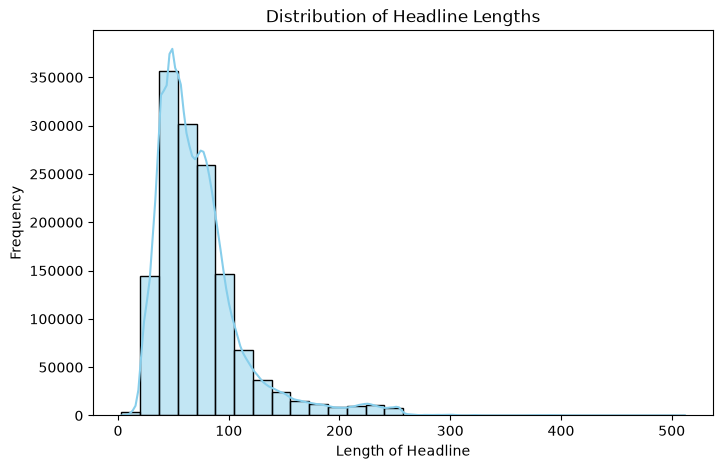

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns


df['headline_length'] = df['headline'].apply(len)

plt.figure(figsize=(8, 5))
sns.histplot(df['headline_length'], bins=30, kde=True, color='skyblue')
plt.title('Distribution of Headline Lengths')
plt.xlabel('Length of Headline')
plt.ylabel('Frequency')
plt.show()


## Trends over TIme


In [17]:
%pip install matplotlib seaborn


[notice] A new release of pip is available: 25.3 -> 26.1.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


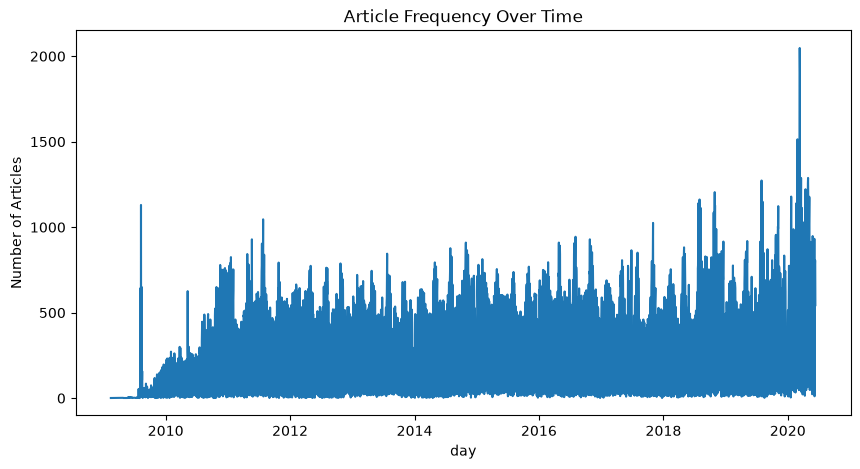

In [18]:
df['date'] = pd.to_datetime(df['date'], format='mixed', utc=True)
df['day'] = df['date'].dt.tz_convert('America/New_York').dt.date
daily_counts = df.groupby('day').size()

import matplotlib.pyplot as plt
daily_counts.plot(title="Article Frequency Over Time", figsize=(10, 5))
plt.ylabel("Number of Articles")
plt.show()


## Topic Modeling and Keyword Extraction

/tmp/ipykernel_93145/3963880042.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_publishers.values, y=top_publishers.index, palette='muted')


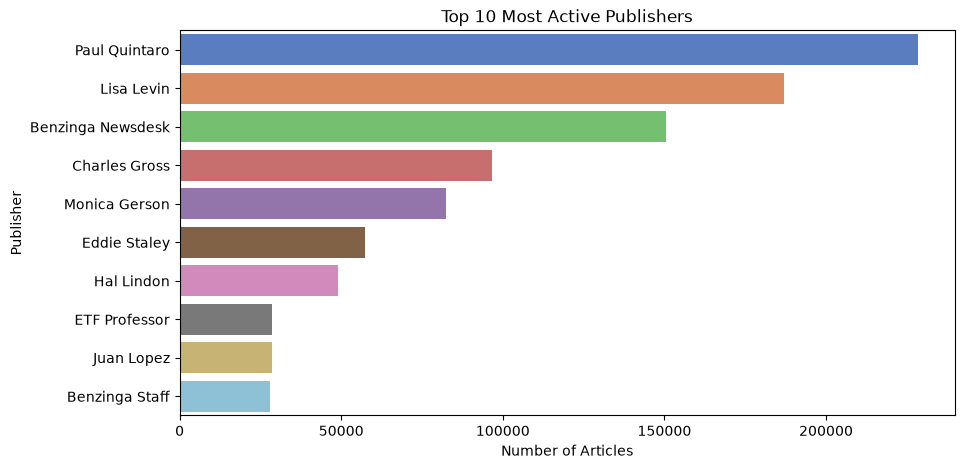

In [19]:
top_publishers = df['publisher'].value_counts().head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_publishers.values, y=top_publishers.index, palette='muted')
plt.title('Top 10 Most Active Publishers')
plt.xlabel('Number of Articles')
plt.ylabel('Publisher')
plt.show()


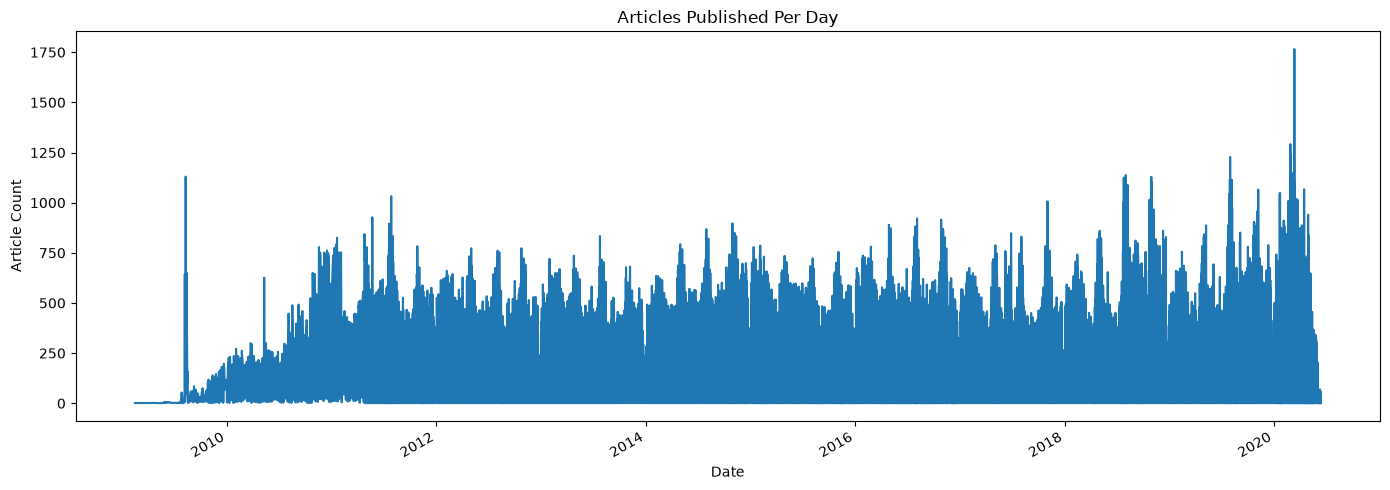

In [20]:
daily_counts = df.groupby('date').size()

plt.figure(figsize=(14, 5))
daily_counts.plot()
plt.title('Articles Published Per Day')
plt.xlabel('Date')
plt.ylabel('Article Count')
plt.tight_layout()
plt.show()


/tmp/ipykernel_93145/844973458.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts, y=keywords, palette='viridis')


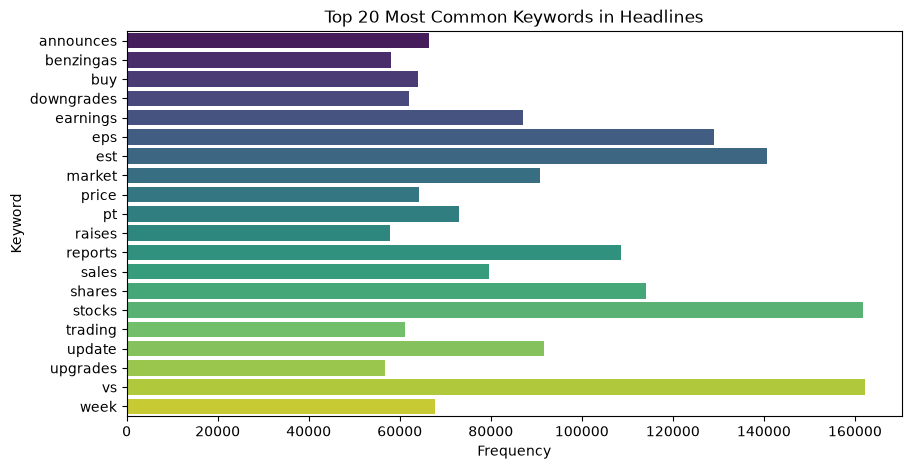

In [21]:
import re
from sklearn.feature_extraction.text import CountVectorizer

# Clean headlines
def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    return text

df['clean_headline'] = df['headline'].apply(clean_text)

# Vectorize and extract top words
vectorizer = CountVectorizer(stop_words='english', max_features=20)
X = vectorizer.fit_transform(df['clean_headline'])

keywords = vectorizer.get_feature_names_out()
counts = X.toarray().sum(axis=0)

plt.figure(figsize=(10, 5))
sns.barplot(x=counts, y=keywords, palette='viridis')
plt.title('Top 20 Most Common Keywords in Headlines')
plt.xlabel('Frequency')
plt.ylabel('Keyword')
plt.show()


In [22]:

from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(stop_words='english', max_features=20)
X = vectorizer.fit_transform(df['headline'].fillna(''))
print(vectorizer.get_feature_names_out())


['announces' 'benzinga' 'buy' 'downgrades' 'earnings' 'eps' 'est' 'market'
 'mid' 'price' 'pt' 'raises' 'reports' 'sales' 'shares' 'stocks' 'trading'
 'update' 'vs' 'week']


## Publisher Domain Analysis

In [23]:
df['domain'] = df['publisher'].str.extract(r'@(\w+\.\w+)')
print(df['domain'].value_counts().head(10))


domain
benzinga.com              7937
gmail.com                  139
andyswan.com                 5
investdiva.com               2
tothetick.com                2
eosdetroit.io                1
forextraininggroup.com       1
stockmetrix.net              1
Name: count, dtype: int64


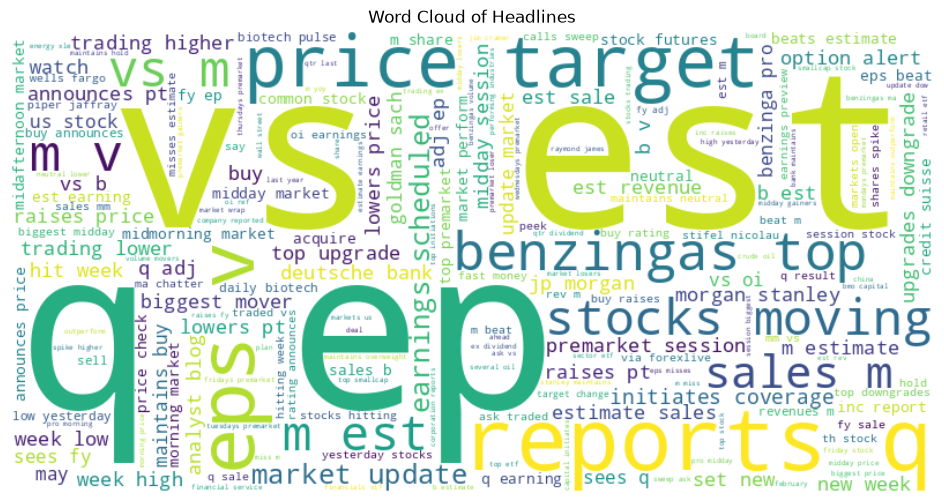

In [24]:
from wordcloud import WordCloud
text = ' '.join(df['clean_headline'])

plt.figure(figsize=(12, 6))
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud of Headlines')
plt.show()


/tmp/ipykernel_93145/2177915907.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='hour', data=df, palette='coolwarm')


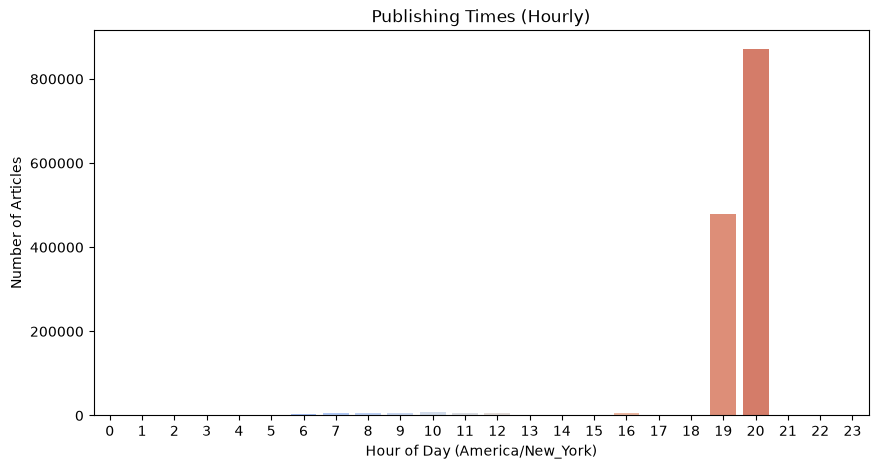

In [28]:
if 'hour' not in df.columns:
    df['hour'] = df['date'].dt.tz_convert('America/New_York').dt.hour

plt.figure(figsize=(10, 5))
sns.countplot(x='hour', data=df, palette='coolwarm')
plt.title('Publishing Times (Hourly)')
plt.xlabel('Hour of Day (America/New_York)')
plt.ylabel('Number of Articles')
plt.show()
